# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Fathia Nabila Naina
- **Email:** fathiianabila@gmail.com
- **ID Dicoding:** DS322B6X0585

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

Dataset ini berisi catatan penyewaan sepeda Capital Bikeshare (Washington D.C.) selama 2011–2012. Pengguna dibedakan menjadi **casual** (pengguna tidak berlangganan) dan **registered** (pelanggan terdaftar). Dua pertanyaan bisnis berikut disusun dengan kerangka SMART dan dijawab dengan data harian.

- **Pertanyaan 1:** Berapa persentase penyewaan oleh pengguna casual terhadap total penyewaan pada hari kerja dibandingkan hari libur/akhir pekan selama 2011–2012, dan berapa rata-rata penyewaan harian casual dan registered pada masing-masing kelompok hari? Hasilnya dipakai tim pemasaran untuk menentukan kapan dan kepada siapa promosi paket sewa (wisata atau komuter) diarahkan.
- **Pertanyaan 2:** Musim apa yang memiliki rata-rata penyewaan harian tertinggi dan terendah, dan berapa persen pertumbuhan rata-rata penyewaan harian pada tiap musim dari 2011 ke 2012? Hasilnya dipakai tim operasional untuk merencanakan jumlah armada dan jadwal perawatan sepeda per musim.

## Import Semua Packages/Library yang Digunakan

In [136]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

Dataset memiliki dua file: `day.csv` (agregasi harian) dan `hour.csv` (agregasi per jam). Kedua pertanyaan di atas membandingkan kelompok hari dan musim sehingga cukup dijawab dengan data harian. Karena itu hanya `day.csv` yang dimuat, dan `hour.csv` tidak dipakai.

#### Load df day

In [137]:
day_df = pd.read_csv("data/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**
- `day.csv` berisi 731 baris dan 16 kolom, satu baris per hari dari 1 Januari 2011 sampai 31 Desember 2012 (365 hari pada 2011 dan 366 hari pada 2012).
- Kolom `casual` dan `registered` memisahkan jenis pengguna, dan `cnt` adalah jumlah keduanya, sehingga data ini cukup untuk menjawab kedua pertanyaan tanpa `hour.csv`.

### Assessing Data

#### Memeriksa struktur, missing value, duplikat, dan konsistensi

In [138]:
day_df.info()
print("\nMissing value :", day_df.isna().sum().sum())
print("Duplikat      :", day_df.duplicated().sum())
print("Tanggal unik  :", day_df["dteday"].is_unique)
print("cnt = casual + registered di semua baris:", (day_df["cnt"] == day_df["casual"] + day_df["registered"]).all())
print("workingday = 1 pada Sabtu/Minggu         :", ((day_df["workingday"] == 1) & day_df["weekday"].isin([0, 6])).sum())
print("holiday dan workingday = 1 bersamaan     :", ((day_df["holiday"] == 1) & (day_df["workingday"] == 1)).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Missing value : 0
Duplikat      : 0
Tanggal unik  : True
cnt = casual + registered di semua 

#### Masalah 1: tipe data tanggal salah

In [139]:
print("Tipe data dteday:", day_df["dteday"].dtype)
print("Contoh nilai    :", day_df["dteday"].iloc[0])

Tipe data dteday: object
Contoh nilai    : 2011-01-01


#### Masalah 2: nilai tidak valid pada kelembapan (`hum` = 0)

In [140]:
print("Jumlah baris hum = 0:", (day_df["hum"] == 0).sum())
day_df.loc[day_df["hum"] == 0, ["dteday", "hum", "temp", "weathersit", "cnt"]]

Jumlah baris hum = 0: 1


,dteday,hum,temp,weathersit,cnt
68,2011-03-10,0.0,0.389091,3,623


#### Masalah 3: label musim pada Readme tidak sesuai dengan tanggal (nilai tidak akurat)

In [141]:
# Readme menyebut: 1 = springer, 2 = summer, 3 = fall, 4 = winter.
# Bandingkan dengan tanggal sebenarnya saat kode musim berganti (tahun 2011).
tmp = day_df.assign(tanggal=pd.to_datetime(day_df["dteday"]))
ganti = tmp[tmp["season"].ne(tmp["season"].shift())]
print("Tanggal saat kode musim mulai berlaku (2011):")
print(ganti.loc[ganti["tanggal"].dt.year == 2011, ["dteday", "season"]].to_string(index=False))
print("\nRata-rata penyewaan harian per kode musim:")
print(day_df.groupby("season")["cnt"].mean().round(0))

Tanggal saat kode musim mulai berlaku (2011):
    dteday  season
2011-01-01       1
2011-03-21       2
2011-06-21       3
2011-09-23       4
2011-12-21       1

Rata-rata penyewaan harian per kode musim:
season
1    2604.0
2    4992.0
3    5644.0
4    4728.0
Name: cnt, dtype: float64


#### Masalah 4: kolom kategorikal masih berupa kode dan nilai cuaca masih ternormalisasi

In [142]:
print(day_df[["season", "yr", "weekday", "weathersit"]].apply(lambda s: sorted(s.unique())))
print()
print(day_df[["temp", "atemp", "hum", "windspeed"]].describe().loc[["min", "max"]])

season                 [1, 2, 3, 4]
yr                           [0, 1]
weekday       [0, 1, 2, 3, 4, 5, 6]
weathersit                [1, 2, 3]
dtype: object

         temp     atemp     hum  windspeed
min  0.059130  0.079070  0.0000   0.022392
max  0.861667  0.840896  0.9725   0.507463


#### Masalah 5: outlier pada `casual`, `windspeed`, dan `hum`

In [143]:
def count_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

for col in ["casual", "registered", "cnt", "windspeed", "hum", "temp"]:
    print(f"{col:11s}: {count_outliers(day_df[col])} outlier (IQR)")

print("\nHari dengan penyewaan terendah:")
day_df.nsmallest(3, "cnt")[["dteday", "cnt", "weathersit", "windspeed"]]

casual     : 44 outlier (IQR)
registered : 0 outlier (IQR)
cnt        : 0 outlier (IQR)
windspeed  : 13 outlier (IQR)
hum        : 2 outlier (IQR)
temp       : 0 outlier (IQR)

Hari dengan penyewaan terendah:


,dteday,cnt,weathersit,windspeed
667,2012-10-29,22,3,0.358200
26,2011-01-27,431,1,0.113837
725,2012-12-26,441,3,0.316546


**Steps to Take:**
- Ubah `dteday` menjadi `datetime`.
- Ganti `hum` = 0 (tidak valid, kelembapan nyata tidak mungkin 0%) dengan NaN lalu isi dengan interpolasi linear.
- Beri label musim berdasarkan **tanggal sebenarnya**, bukan berdasarkan Readme: kode 1 = Dingin, 2 = Semi, 3 = Panas, 4 = Gugur.
- Beri label pada `yr`, `weekday`, `weathersit`, buat kolom `tipe_hari`, dan kembalikan `temp`, `atemp`, `hum`, `windspeed` ke satuan aslinya (°C, %, km/jam) sesuai keterangan dataset.
- Outlier `casual`, `windspeed`, dan `hum` **dipertahankan**: nilainya wajar (akhir pekan cerah, hari berangin, cuaca ekstrem) dan bukan kesalahan input. Outlier hanya dicatat.

**Insight:**
- Tidak ada missing value maupun baris duplikat, dan pemeriksaan konsistensi lolos: `cnt` selalu sama dengan `casual` + `registered`, serta tidak ada hari kerja yang jatuh pada Sabtu/Minggu atau hari libur.
- Kolom `dteday` masih bertipe string sehingga belum bisa dipakai untuk analisis berbasis waktu.
- Ada satu nilai tidak valid: `hum` = 0 pada 10 Maret 2011 (kelembapan nyata tidak mungkin 0%).
- Label musim pada Readme tidak sesuai dengan tanggal. Kode 1 mulai berlaku pada 1 Januari dan 21 Desember, kode 2 pada 21 Maret, kode 3 pada 21 Juni, dan kode 4 pada 23 September. Jadi kode 1 sebenarnya musim dingin (rata-rata penyewaan terendah, sekitar 2.604 per hari), bukan "springer" seperti tertulis di Readme.
- Terdapat outlier pada `casual` (44 nilai), `windspeed` (13), dan `hum` (2). Penyewaan terendah terjadi pada 29 Oktober 2012 (hanya 22 penyewaan, cuaca hujan/salju ringan dengan angin kencang), bertepatan dengan periode Badai Sandy yang disebut Readme dataset.
- Data harian hanya memuat kondisi cuaca 1 sampai 3, tidak ada kategori 4 (hujan/salju lebat).

### Cleaning Data

#### Memperbaiki tipe data tanggal

In [144]:
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
print("Tipe data dteday:", day_df["dteday"].dtype)

Tipe data dteday: datetime64[ns]


#### Memperbaiki nilai kelembapan tidak valid

In [145]:
day_df["hum"] = day_df["hum"].replace(0, np.nan)
day_df["hum"] = day_df["hum"].interpolate(method="linear")

print("hum = 0 atau NaN tersisa:", day_df["hum"].isna().sum() + (day_df["hum"] == 0).sum())
day_df.loc[day_df["dteday"].between("2011-03-09", "2011-03-11"), ["dteday", "hum"]]

hum = 0 atau NaN tersisa: 0


,dteday,hum
67,2011-03-09,0.775417
68,2011-03-10,0.712491
69,2011-03-11,0.649565


#### Memberi label kategori dan mengembalikan satuan asli

In [146]:
musim_map = {1: "Dingin", 2: "Semi", 3: "Panas", 4: "Gugur"}
cuaca_map = {1: "Cerah", 2: "Berkabut", 3: "Hujan/Salju Ringan", 4: "Hujan/Salju Lebat"}
hari_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}

day_df["tahun"] = day_df["yr"].map({0: 2011, 1: 2012})
day_df["musim"] = day_df["season"].map(musim_map)
day_df["cuaca"] = day_df["weathersit"].map(cuaca_map)
day_df["hari"] = day_df["weekday"].map(hari_map)
day_df["tipe_hari"] = np.where(day_df["workingday"] == 1, "Hari Kerja", "Libur/Akhir Pekan")

day_df["suhu_c"] = day_df["temp"] * 41
day_df["suhu_terasa_c"] = day_df["atemp"] * 50
day_df["kelembapan_pct"] = day_df["hum"] * 100
day_df["kecepatan_angin"] = day_df["windspeed"] * 67

day_df[["dteday", "tahun", "musim", "cuaca", "hari", "tipe_hari", "suhu_c", "kelembapan_pct", "cnt"]].head()

,dteday,tahun,musim,cuaca,hari,tipe_hari,suhu_c,kelembapan_pct,cnt
0,2011-01-01,2011,Dingin,Berkabut,Sabtu,Libur/Akhir Pekan,14.110847,80.5833,985
1,2011-01-02,2011,Dingin,Berkabut,Minggu,Libur/Akhir Pekan,14.902598,69.6087,801
2,2011-01-03,2011,Dingin,Cerah,Senin,Hari Kerja,8.050924,43.7273,1349
3,2011-01-04,2011,Dingin,Cerah,Selasa,Hari Kerja,8.200000,59.0435,1562
4,2011-01-05,2011,Dingin,Cerah,Rabu,Hari Kerja,9.305237,43.6957,1600


In [147]:
# Pemeriksaan hasil: tanggal saat musim berganti (2011) setelah diberi label
ganti_musim = day_df[day_df["musim"].ne(day_df["musim"].shift())]
ganti_musim.loc[ganti_musim["tahun"] == 2011, ["dteday", "musim"]]

,dteday,musim
0,2011-01-01,Dingin
79,2011-03-21,Semi
171,2011-06-21,Panas
265,2011-09-23,Gugur
354,2011-12-21,Dingin


**Insight:**
- `dteday` kini bertipe `datetime`, dan `hum` pada 10 Maret 2011 terisi sekitar 71,2% hasil interpolasi dari hari sebelum dan sesudahnya (77,5% dan 65,0%).
- Musim kini berlabel berdasarkan tanggal sebenarnya: Dingin (21 Desember–20 Maret, 181 hari), Semi (21 Maret–20 Juni, 184 hari), Panas (21 Juni–22 September, 188 hari), dan Gugur (23 September–20 Desember, 178 hari).
- Kolom suhu, kelembapan, dan angin sudah dalam satuan asli: suhu rata-rata 20,3°C (rentang 2,4–35,3°C), kelembapan rata-rata 62,9%, dan kecepatan angin rata-rata 12,8 km/jam.

## Exploratory Data Analysis (EDA)

### Ringkasan statistik

In [148]:
day_df[["suhu_c", "kelembapan_pct", "kecepatan_angin", "casual", "registered", "cnt"]].describe().round(1)

,suhu_c,kelembapan_pct,kecepatan_angin,casual,registered,cnt
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,20.3,62.9,12.8,848.2,3656.2,4504.3
std,7.5,14.1,5.2,686.6,1560.3,1937.2
min,2.4,18.8,1.5,2.0,20.0,22.0
25%,13.8,52.1,9.0,315.5,2497.0,3152.0
50%,20.4,62.7,12.1,713.0,3662.0,4548.0
75%,26.9,73.0,15.6,1096.0,4776.5,5956.0
max,35.3,97.2,34.0,3410.0,6946.0,8714.0


### Explore: pengguna casual dan registered pada hari kerja vs libur/akhir pekan (Pertanyaan 1)

In [149]:
urut_tipe = ["Hari Kerja", "Libur/Akhir Pekan"]

tipe_df = (
    day_df.groupby("tipe_hari")
    .agg(jumlah_hari=("cnt", "size"),
         total_casual=("casual", "sum"),
         total_registered=("registered", "sum"),
         total_penyewaan=("cnt", "sum"),
         rata2_casual=("casual", "mean"),
         rata2_registered=("registered", "mean"),
         rata2_total=("cnt", "mean"))
    .loc[urut_tipe]
)
tipe_df["persen_casual"] = tipe_df["total_casual"] / tipe_df["total_penyewaan"] * 100
tipe_df.round(1)

,jumlah_hari,total_casual,total_registered,total_penyewaan,rata2_casual,rata2_registered,rata2_total,persen_casual
tipe_hari,,,,,,,,
Hari Kerja,500,303285,1989125,2292410,606.6,3978.2,4584.8,13.2
Libur/Akhir Pekan,231,316732,683537,1000269,1371.1,2959.0,4330.2,31.7


In [150]:
kerja, libur = tipe_df.loc["Hari Kerja"], tipe_df.loc["Libur/Akhir Pekan"]

print(f"Persentase casual, hari kerja       : {kerja['persen_casual']:.1f}%")
print(f"Persentase casual, libur/akhir pekan: {libur['persen_casual']:.1f}%")
print(f"Casual per hari, libur dibanding kerja     : {libur['rata2_casual'] / kerja['rata2_casual']:.2f} kali")
print(f"Registered per hari, kerja dibanding libur : {kerja['rata2_registered'] / libur['rata2_registered']:.2f} kali")
print(f"Persentase casual keseluruhan       : {day_df['casual'].sum() / day_df['cnt'].sum() * 100:.1f}%")

Persentase casual, hari kerja       : 13.2%
Persentase casual, libur/akhir pekan: 31.7%
Casual per hari, libur dibanding kerja     : 2.26 kali
Registered per hari, kerja dibanding libur : 1.34 kali
Persentase casual keseluruhan       : 18.8%


### Explore: musim dan pertumbuhan penyewaan 2011 ke 2012 (Pertanyaan 2)

In [151]:
urut_musim = ["Dingin", "Semi", "Panas", "Gugur"]

musim_df = (
    day_df.groupby("musim")
    .agg(jumlah_hari=("cnt", "size"), rata2_harian=("cnt", "mean"), median_harian=("cnt", "median"))
    .loc[urut_musim]
    .round(0)
)
print("Musim tertinggi:", musim_df["rata2_harian"].idxmax(), "| terendah:", musim_df["rata2_harian"].idxmin())
musim_df

Musim tertinggi: Panas | terendah: Dingin


,jumlah_hari,rata2_harian,median_harian
musim,,,
Dingin,181,2604.0,2209.0
Semi,184,4992.0,4942.0
Panas,188,5644.0,5354.0
Gugur,178,4728.0,4634.0


In [152]:
tahun_musim = day_df.pivot_table(index="musim", columns="tahun", values="cnt", aggfunc="mean").loc[urut_musim]
tahun_musim["pertumbuhan_%"] = (tahun_musim[2012] / tahun_musim[2011] - 1) * 100

rata_tahun = day_df.groupby("tahun")["cnt"].mean()
pertumbuhan_total = (rata_tahun[2012] / rata_tahun[2011] - 1) * 100
print(f"Rata-rata harian 2011: {rata_tahun[2011]:,.0f} | 2012: {rata_tahun[2012]:,.0f} | pertumbuhan: {pertumbuhan_total:.1f}%")
tahun_musim.round(1)

Rata-rata harian 2011: 3,406 | 2012: 5,600 | pertumbuhan: 64.4%


tahun,2011,2012,pertumbuhan_%
musim,,,
Dingin,1666.7,3531.3,111.9
Semi,3775.2,6209.5,64.5
Panas,4464.4,6824.2,52.9
Gugur,3664.5,5791.9,58.1


**Insight:**
- Pertanyaan 1: dari 731 hari, ada 500 hari kerja dan 231 hari libur/akhir pekan. Pengguna casual hanya 13,2% dari total penyewaan pada hari kerja, tetapi 31,7% pada hari libur/akhir pekan (18,8% secara keseluruhan).
- Rata-rata penyewaan casual per hari pada hari libur (1.371) adalah 2,26 kali hari kerja (607). Sebaliknya, pengguna registered lebih banyak pada hari kerja (3.978 per hari) dibanding hari libur (2.959), sekitar 1,34 kali.
- Total penyewaan rata-rata per hari hampir sama (4.585 pada hari kerja dan 4.330 pada hari libur), jadi jenis hari lebih mengubah komposisi pengguna daripada jumlah penyewaan.
- Pertanyaan 2: rata-rata penyewaan harian tertinggi ada pada musim Panas (5.644) dan terendah pada musim Dingin (2.604), diikuti Semi (4.992) dan Gugur (4.728).
- Rata-rata harian naik dari 3.406 (2011) menjadi 5.600 (2012), pertumbuhan 64,4%. Pertumbuhan per musim: Dingin 111,9%, Semi 64,5%, Gugur 58,1%, dan Panas 52,9%. Musim Dingin tumbuh paling tinggi dalam persen karena basisnya kecil (1.667 menjadi 3.531), sedangkan kenaikan terbesar dalam angka absolut ada pada musim Semi (+2.434 per hari).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Berapa persentase pengguna casual pada hari kerja dibanding libur/akhir pekan?

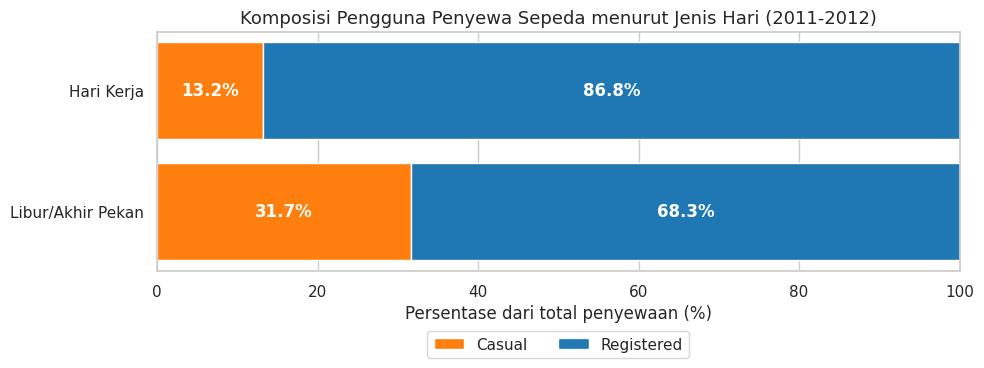

In [153]:
warna_casual, warna_reg = "#ff7f0e", "#1f77b4"

persen = tipe_df[["total_casual", "total_registered"]].div(tipe_df["total_penyewaan"], axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(urut_tipe, persen["total_casual"], color=warna_casual, label="Casual")
ax.barh(urut_tipe, persen["total_registered"], left=persen["total_casual"], color=warna_reg, label="Registered")
for i, tipe in enumerate(urut_tipe):
    c = persen.loc[tipe, "total_casual"]
    ax.text(c / 2, i, f"{c:.1f}%", ha="center", va="center", color="white", fontweight="bold")
    ax.text(c + (100 - c) / 2, i, f"{100 - c:.1f}%", ha="center", va="center", color="white", fontweight="bold")
ax.set_title("Komposisi Pengguna Penyewa Sepeda menurut Jenis Hari (2011-2012)", fontsize=13)
ax.set_xlabel("Persentase dari total penyewaan (%)")
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
plt.tight_layout()
plt.show()

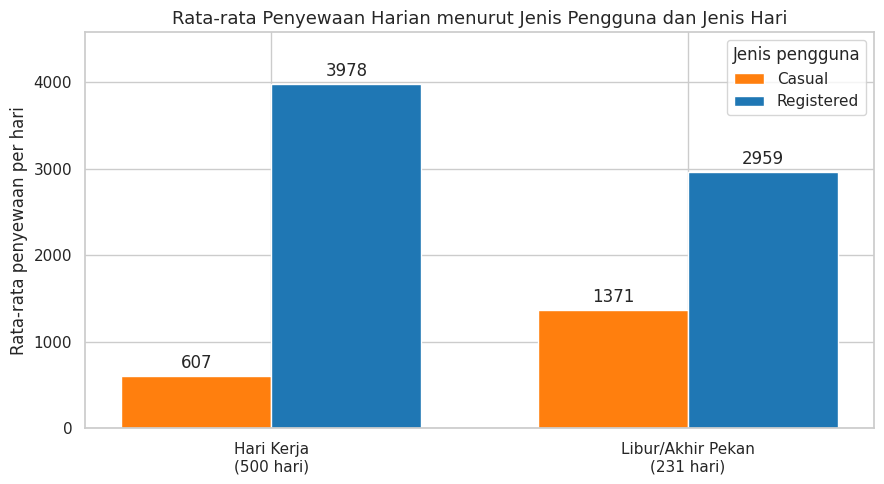

In [154]:
x = np.arange(len(urut_tipe))
lebar = 0.36

fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - lebar / 2, tipe_df["rata2_casual"], lebar, color=warna_casual, label="Casual")
b2 = ax.bar(x + lebar / 2, tipe_df["rata2_registered"], lebar, color=warna_reg, label="Registered")
ax.bar_label(b1, fmt="%.0f", padding=3)
ax.bar_label(b2, fmt="%.0f", padding=3)
ax.set_xticks(x)
ax.set_xticklabels([f"{t}\n({int(n)} hari)" for t, n in zip(urut_tipe, tipe_df["jumlah_hari"])])
ax.set_title("Rata-rata Penyewaan Harian menurut Jenis Pengguna dan Jenis Hari", fontsize=13)
ax.set_ylabel("Rata-rata penyewaan per hari")
ax.set_ylim(0, tipe_df[["rata2_casual", "rata2_registered"]].max().max() * 1.15)
ax.legend(title="Jenis pengguna")
plt.tight_layout()
plt.show()

### Pertanyaan 2: Musim apa yang paling ramai dan seberapa besar pertumbuhannya dari 2011 ke 2012?

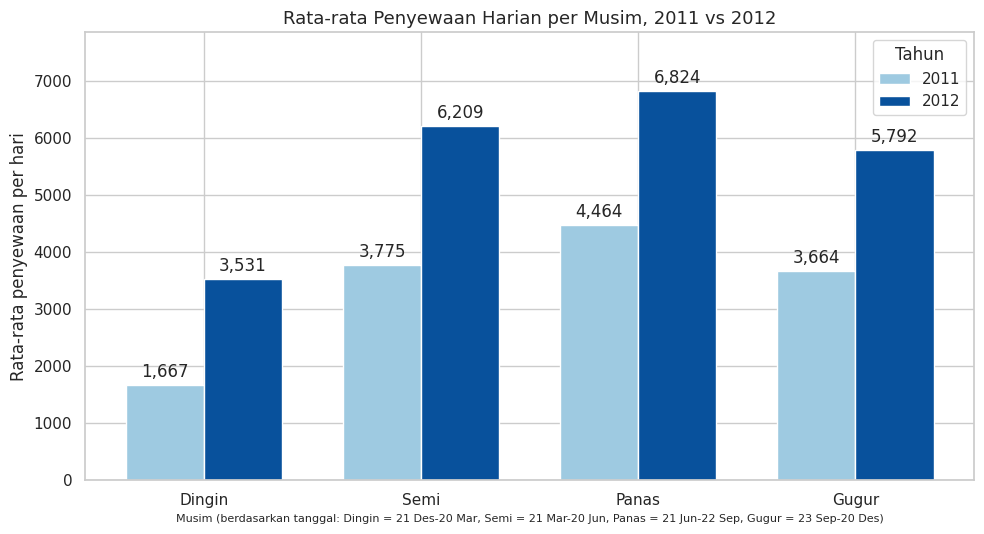

In [155]:
x = np.arange(len(urut_musim))
lebar = 0.36

fig, ax = plt.subplots(figsize=(10, 5.5))
b1 = ax.bar(x - lebar / 2, tahun_musim[2011], lebar, color="#9ecae1", label="2011")
b2 = ax.bar(x + lebar / 2, tahun_musim[2012], lebar, color="#08519c", label="2012")
ax.bar_label(b1, fmt="{:,.0f}", padding=3)
ax.bar_label(b2, fmt="{:,.0f}", padding=3)
ax.set_xticks(x)
ax.set_xticklabels(urut_musim)
ax.set_title("Rata-rata Penyewaan Harian per Musim, 2011 vs 2012", fontsize=13)
ax.set_xlabel("Musim (berdasarkan tanggal: Dingin = 21 Des-20 Mar, Semi = 21 Mar-20 Jun, Panas = 21 Jun-22 Sep, Gugur = 23 Sep-20 Des)", fontsize=8)
ax.set_ylabel("Rata-rata penyewaan per hari")
ax.set_ylim(0, tahun_musim[2012].max() * 1.15)
ax.legend(title="Tahun")
plt.tight_layout()
plt.show()

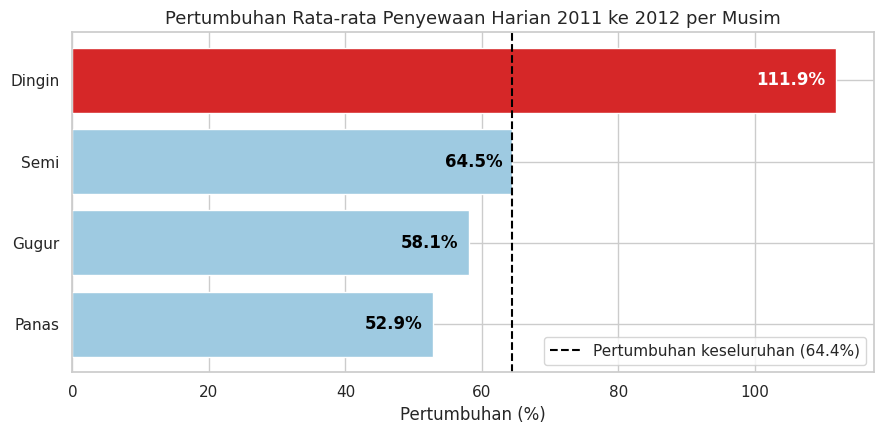

In [156]:
pert = tahun_musim["pertumbuhan_%"].sort_values(ascending=True)
warna = ["#d62728" if m == pert.idxmax() else "#9ecae1" for m in pert.index]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(pert.index, pert.values, color=warna)
ax.axvline(pertumbuhan_total, color="black", linestyle="--", label=f"Pertumbuhan keseluruhan ({pertumbuhan_total:.1f}%)")
for i, (m, v) in enumerate(pert.items()):
    ax.text(v - 1.5, i, f"{v:.1f}%", va="center", ha="right", fontweight="bold",
            color="white" if m == pert.idxmax() else "black")
ax.set_title("Pertumbuhan Rata-rata Penyewaan Harian 2011 ke 2012 per Musim", fontsize=13)
ax.set_xlabel("Pertumbuhan (%)")
ax.set_xlim(0, pert.max() * 1.05)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Insight:**
- Pertanyaan 1: pada hari kerja, sekitar 87% penyewaan berasal dari pengguna registered. Pada hari libur/akhir pekan porsi casual melonjak menjadi hampir sepertiga, dan jumlah casual per hari lebih dari dua kali lipat.
- Pertanyaan 2: musim Panas paling ramai pada kedua tahun, sedangkan musim Dingin paling sepi. Semua musim tumbuh minimal 52,9%, dan musim Dingin tumbuh paling tinggi secara persentase dari basis yang rendah, sehingga angka 111,9% jangan dibaca sebagai musim Dingin menjadi ramai.
- Seluruh grafik batang dimulai dari nol agar perbandingan tinggi batang tidak menyesatkan.

## Analisis Lanjutan (Opsional)

Teknik yang dipakai adalah **binning / manual grouping** (tanpa machine learning). Hari dikelompokkan menjadi tiga tingkat permintaan (Rendah, Sedang, Tinggi) berdasarkan jumlah penyewaan hariannya, dengan batas pada sepertiga dan dua pertiga distribusi. Batas dihitung **terpisah untuk tiap tahun** supaya pertumbuhan 2012 tidak membuat hampir semua hari 2012 terlihat "Tinggi". Tujuannya mengetahui musim dan jenis hari apa yang paling sering menghasilkan hari berpermintaan tinggi, sehingga perencanaan armada tidak hanya melihat rata-rata. RFM tidak relevan karena data tidak memuat pelanggan individu, dan analisis geospasial tidak relevan karena data tidak memuat lokasi.

Batas tingkat permintaan (penyewaan per hari):
       batas_rendah_sedang  batas_sedang_tinggi
tahun                                          
2011                2720.0               4333.0
2012                5101.0               6746.0


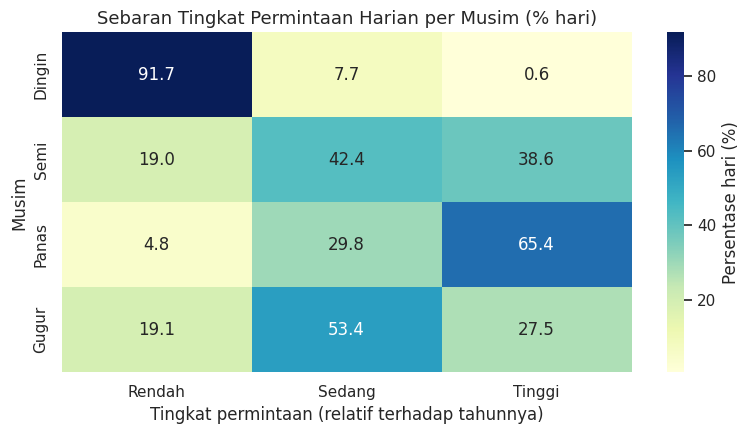

kategori_permintaan,Rendah,Sedang,Tinggi
musim,,,
Dingin,91.7,7.7,0.6
Semi,19.0,42.4,38.6
Panas,4.8,29.8,65.4
Gugur,19.1,53.4,27.5


In [157]:
batas_tahun = day_df.groupby("tahun")["cnt"].quantile([1 / 3, 2 / 3]).unstack()
batas_tahun.columns = ["batas_rendah_sedang", "batas_sedang_tinggi"]
print("Batas tingkat permintaan (penyewaan per hari):")
print(batas_tahun.round(0))

day_df["kategori_permintaan"] = day_df.groupby("tahun")["cnt"].transform(
    lambda s: pd.qcut(s, 3, labels=["Rendah", "Sedang", "Tinggi"]).astype(str)
)
day_df["kategori_permintaan"] = pd.Categorical(
    day_df["kategori_permintaan"], categories=["Rendah", "Sedang", "Tinggi"], ordered=True
)

pivot_musim = (pd.crosstab(day_df["musim"], day_df["kategori_permintaan"], normalize="index") * 100).loc[urut_musim]

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pivot_musim, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax,
            cbar_kws={"label": "Persentase hari (%)"})
ax.set_title("Sebaran Tingkat Permintaan Harian per Musim (% hari)", fontsize=13)
ax.set_xlabel("Tingkat permintaan (relatif terhadap tahunnya)")
ax.set_ylabel("Musim")
plt.tight_layout()
plt.show()
pivot_musim.round(1)

In [158]:
# Tingkat permintaan menurut jenis hari dan rata-rata penyewaan tiap tingkat
print("Persentase hari menurut jenis hari:")
display((pd.crosstab(day_df["tipe_hari"], day_df["kategori_permintaan"], normalize="index") * 100).round(1))
print("Rata-rata penyewaan harian dan persentase casual menurut tingkat permintaan:")
display(day_df.groupby("kategori_permintaan", observed=True).agg(
    jumlah_hari=("cnt", "size"), rata2_cnt=("cnt", "mean"),
    persen_casual=("casual", lambda s: s.sum() / day_df.loc[s.index, "cnt"].sum() * 100)).round(1))

Persentase hari menurut jenis hari:


kategori_permintaan,Rendah,Sedang,Tinggi
tipe_hari,,,
Hari Kerja,31.6,34.0,34.4
Libur/Akhir Pekan,37.2,31.6,31.2


Rata-rata penyewaan harian dan persentase casual menurut tingkat permintaan:


,jumlah_hari,rata2_cnt,persen_casual
kategori_permintaan,,,
Rendah,244,2591.2,12.8
Sedang,243,4801.3,18.4
Tinggi,244,6121.8,21.7


**Insight:**
- Batas tingkat permintaan dihitung per tahun: pada 2011 Rendah di bawah 2.720 dan Tinggi di atas 4.333 penyewaan per hari, sedangkan pada 2012 batasnya 5.101 dan 6.746.
- Musim Dingin hampir tidak pernah menghasilkan hari berpermintaan tinggi (0,6% hari) dan 91,7% harinya berpermintaan rendah. Musim Panas sebaliknya, 65,4% harinya berpermintaan tinggi dan hanya 4,8% yang rendah. Musim Semi (38,6%) dan Gugur (27,5%) berada di tengah.
- Jenis hari hampir tidak membedakan tingkat permintaan: hari kerja punya 34,4% hari Tinggi dan hari libur 31,2%, sejalan dengan total rata-rata harian yang hampir sama.
- Semakin ramai harinya, semakin besar porsi pengguna casual: 12,8% pada hari Rendah, 18,4% pada hari Sedang, dan 21,7% pada hari Tinggi.

### Menyimpan data bersih untuk dashboard

In [159]:
os.makedirs("dashboard", exist_ok=True)

main_data = day_df[["dteday", "tahun", "musim", "cuaca", "hari", "tipe_hari", "suhu_c",
                    "kelembapan_pct", "kecepatan_angin", "casual", "registered", "cnt",
                    "kategori_permintaan"]].copy()
main_data["kategori_permintaan"] = main_data["kategori_permintaan"].astype(str)
main_data.to_csv("dashboard/main_data.csv", index=False)
print("main_data.csv:", main_data.shape)

main_data.csv: (731, 13)


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada 2011–2012, pengguna casual menyumbang 13,2% penyewaan pada hari kerja dibanding 31,7% pada hari libur/akhir pekan. Rata-rata penyewaan casual per hari pada hari libur (1.371) adalah 2,26 kali hari kerja (607), sedangkan pengguna registered lebih banyak pada hari kerja (3.978 per hari) dibanding hari libur (2.959). Total penyewaan per hari hampir sama (4.585 vs 4.330), sehingga jenis hari mengubah siapa yang menyewa, bukan seberapa banyak sepeda disewa.
- **Conclusion pertanyaan 2:** Musim Panas memiliki rata-rata penyewaan harian tertinggi (5.644) dan musim Dingin terendah (2.604, sekitar 46% dari musim Panas). Rata-rata harian tumbuh 64,4% dari 2011 (3.406) ke 2012 (5.600), dengan pertumbuhan per musim sebesar 111,9% (Dingin), 64,5% (Semi), 58,1% (Gugur), dan 52,9% (Panas). Pertumbuhan musim Dingin terlihat besar karena basisnya kecil, sedangkan kenaikan absolut terbesar terjadi pada musim Semi (+2.434 per hari).

**Rekomendasi Action Item:**
- **Pemasaran hari kerja:** karena sekitar 87% penyewa berasal dari pengguna registered, fokuskan pada retensi pelanggan komuter, misalnya paket langganan atau pengingat perpanjangan keanggotaan.
- **Pemasaran akhir pekan dan libur:** arahkan promosi paket harian atau wisata ke pengguna casual, yang porsinya 31,7% dan jumlahnya 2,26 kali lebih banyak per hari. Tawarkan insentif beralih menjadi anggota pada kesempatan ini.
- **Armada per musim:** siapkan armada penuh pada musim Panas dan Semi (65,4% dan 38,6% hari berpermintaan tinggi), dan manfaatkan musim Dingin (91,7% hari berpermintaan rendah) untuk perawatan dan servis massal.
- **Perencanaan kapasitas:** gunakan pertumbuhan 2011 ke 2012 (64,4%) hanya sebagai gambaran awal, karena data baru mencakup dua tahun. Perbarui perencanaan dengan data terbaru sebelum menambah armada.
- **Catatan keterbatasan:** hasil ini menunjukkan pola dan korelasi, bukan sebab-akibat. Faktor lain seperti cuaca harian, suhu, dan peristiwa khusus belum dikendalikan dalam analisis ini.